# Projet 7 – Étape 4 : Approche semi-supervisée

**Objectif :** Comparer deux approches d'entraînement d'un CNN :
- **Supervisé** : entraîné sur les 100 images fortement labelisées uniquement
- **Semi-supervisé** : entraîné d'abord sur les 1406 weak labels, puis affiné sur les 100

**Règle absolue :** le jeu de test est identique pour les deux modèles,  
et jamais vu pendant l'entraînement.

## 0. Imports et configuration

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"  #pour éviter un warning de scikit-learn sur Windows

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT       = Path(".")
DIR_OUTPUT = ROOT / "output"
DIR_CANCER  = ROOT / "avec_labels" / "cancer"
DIR_NORMAL  = ROOT / "avec_labels" / "normal"
DIR_UNLABEL = ROOT / "sans_label"

DEVICE = torch.device("cpu")
print(f"Device : {DEVICE}")

Device : cpu


## 1. Chargement des données

In [2]:
# Données fortement labelisées
images_cancer = sorted(DIR_CANCER.glob("*.jpg"))
images_normal = sorted(DIR_NORMAL.glob("*.jpg"))

chemins_label = [str(p) for p in images_cancer + images_normal]
labels_forts  = [1]*len(images_cancer) + [0]*len(images_normal)

# Données faiblement labelisées (weak labels de l'étape 3)
meta_unlabel  = pd.read_csv(DIR_OUTPUT / "meta_unlabel_clusters.csv")
chemins_unlabel = [str(DIR_UNLABEL / f) for f in meta_unlabel["fichier"]]
labels_faibles  = meta_unlabel["cluster"].tolist()

print(f"Données fortement labelisées : {len(chemins_label)} images")
print(f"Données faiblement labelisées : {len(chemins_unlabel)} images")

Données fortement labelisées : 100 images
Données faiblement labelisées : 1406 images


## 2. Split train/test

On découpe les 100 images labelisées en train (80%) et test (20%).  
Le test set est mis de côté — jamais touché pendant l'entraînement.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    chemins_label, labels_forts,
    test_size=0.2,
    random_state=42,
    stratify=labels_forts   # garde le ratio 50/50 dans train et test
)

print(f"Train : {len(X_train)} images")
print(f"Test  : {len(X_test)} images")
print(f"Distribution test — cancer: {y_test.count(1)}, normal: {y_test.count(0)}")

Train : 80 images
Test  : 20 images
Distribution test — cancer: 10, normal: 10


## 3. Dataset et transforms PyTorch

In [4]:
# Transforms : augmentation pour le train, simple resize pour le test
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ImageDataset(Dataset):
    def __init__(self, chemins, labels, transform):
        self.chemins   = chemins
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.chemins)

    def __getitem__(self, idx):
        img = Image.open(self.chemins[idx]).convert("RGB")
        return self.transform(img), torch.tensor(self.labels[idx], dtype=torch.long)

print("Dataset et transforms définis.")

Dataset et transforms définis.


## 4. Construction du modèle CNN

On utilise ResNet50 pré-entraîné.  
Cette fois on remplace la dernière couche par un classifieur binaire (2 classes).

In [5]:
def construire_modele():
    """Retourne un ResNet50 avec classifieur binaire en sortie."""
    modele = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    
    # Geler toutes les couches convolutionnelles
    for param in modele.parameters():
        param.requires_grad = False
    
    # Remplacer la dernière couche par un classifieur binaire
    modele.fc = nn.Sequential(
        nn.Linear(2048, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 2)   # 2 classes : cancer / normal
    )
    # Seule la nouvelle couche fc est entraînable
    return modele.to(DEVICE)

print("Fonction de construction du modèle définie.")

Fonction de construction du modèle définie.


## 5. Fonctions d'entraînement et d'évaluation

In [6]:
def entrainer(modele, dataloader, n_epochs, lr=1e-3):
    """Entraîne le modèle et retourne l'historique des losses."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(modele.fc.parameters(), lr=lr)
    
    historique = []
    modele.train()
    
    for epoch in range(n_epochs):
        loss_epoch = 0
        for images, labels in dataloader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = modele(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_epoch += loss.item()
        
        loss_moy = loss_epoch / len(dataloader)
        historique.append(loss_moy)
        print(f"  Epoch {epoch+1}/{n_epochs} — loss : {loss_moy:.4f}", end="\r")
    
    print()
    return historique

# ── Nouvelle fonction entrainer avec val loss ──────────────────────────────
def entrainer2(modele, dataloader, n_epochs, lr=1e-3, dl_val=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(modele.fc.parameters(), lr=lr)
    
    historique_train = []
    historique_val   = []
    
    for epoch in range(n_epochs):
        # ── Train ──
        modele.train()
        loss_epoch = 0
        for images, labels in dataloader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = modele(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_epoch += loss.item()
        loss_train = loss_epoch / len(dataloader)
        historique_train.append(loss_train)

        # ── Val ──
        if dl_val is not None:
            modele.eval()
            loss_val_epoch = 0
            with torch.no_grad():
                for images, labels in dl_val:
                    images, labels = images.to(DEVICE), labels.to(DEVICE)
                    outputs = modele(images)
                    loss_val_epoch += criterion(outputs, labels).item()
            loss_val = loss_val_epoch / len(dl_val)
            historique_val.append(loss_val)
            print(f"  Epoch {epoch+1}/{n_epochs} — train: {loss_train:.4f}  val: {loss_val:.4f}", end="\r")
        else:
            print(f"  Epoch {epoch+1}/{n_epochs} — loss: {loss_train:.4f}", end="\r")
    
    print()
    return historique_train, historique_val

def evaluer(modele, dataloader):
    """Retourne accuracy et F1-score sur un dataloader."""
    modele.eval()
    tous_preds, tous_labels = [], []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(DEVICE)
            outputs = modele(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            tous_preds.extend(preds)
            tous_labels.extend(labels.numpy())
    
    acc = accuracy_score(tous_labels, tous_preds)
    f1  = f1_score(tous_labels, tous_preds, average="weighted")
    return acc, f1, tous_preds, tous_labels

print("Fonctions d'entraînement et d'évaluation définies.")

Fonctions d'entraînement et d'évaluation définies.


In [9]:
# ── Split val sur les strong labels ───────────────────────────────────────
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
ds_tr  = ImageDataset(X_tr,  y_tr,  transform_train)
ds_val = ImageDataset(X_val, y_val, transform_test)
dl_tr  = DataLoader(ds_tr,  batch_size=16, shuffle=True)
dl_val = DataLoader(ds_val, batch_size=16, shuffle=False)


# ── Modèle supervisé — 30 epochs pour voir ────────────────────────────────
modele_sup = construire_modele()
hist_sup_train, hist_sup_val = entrainer2(modele_sup, dl_tr, n_epochs=30, dl_val=dl_val)

# ── Semi-sup — weak labels — 20 epochs ────────────────────────────────────
modele_semi = construire_modele()
hist_weak_train, hist_weak_val = entrainer2(modele_semi, dl_weak, n_epochs=20)
# (pas de val sur weak labels — pas de labels fiables)

# ── Semi-sup — fine-tuning — 30 epochs ────────────────────────────────────
hist_fine_train, hist_fine_val = entrainer2(modele_semi, dl_tr, n_epochs=30, lr=1e-4, dl_val=dl_val)


# ── Courbes ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(hist_sup_train, label="train", color="steelblue")
axes[0].plot(hist_sup_val,   label="val",   color="orange")
axes[0].set_title("Supervisé")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(hist_weak_train, label="train weak", color="orange")
axes[1].set_title("Semi-sup — Weak labels")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()

axes[2].plot(hist_fine_train, label="train", color="tomato")
axes[2].plot(hist_fine_val,   label="val",   color="steelblue")
axes[2].set_title("Semi-sup — Fine-tuning")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Loss"); axes[2].legend()

plt.suptitle("Courbes d'entraînement — train vs val", fontsize=13)
plt.tight_layout()
plt.show()

  Epoch 30/30 — train: 0.0307  val: 0.0534


KeyboardInterrupt: 

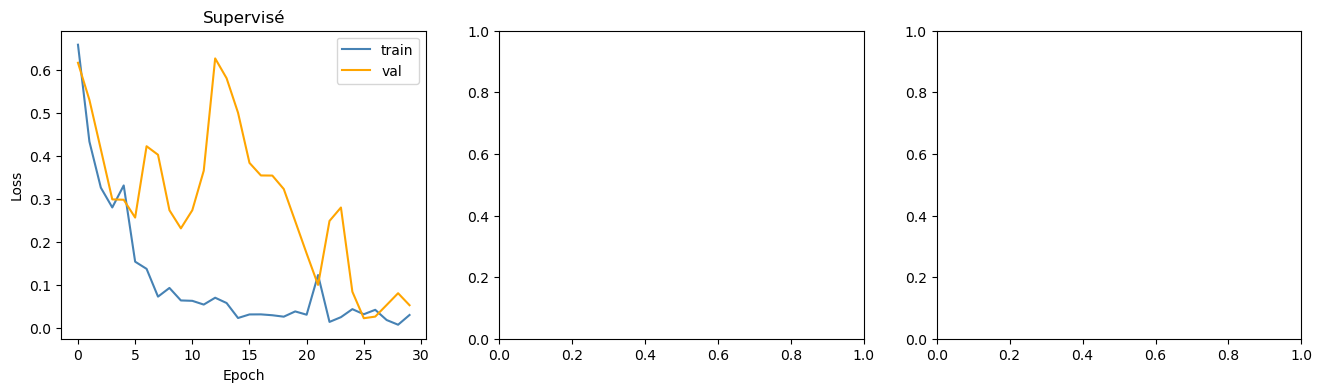

In [10]:
# ── Courbes ───────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(hist_sup_train, label="train", color="steelblue")
axes[0].plot(hist_sup_val,   label="val",   color="orange")
axes[0].set_title("Supervisé")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()


## 6. Modèle supervisé (baseline)

Entraîné sur les 80 images du train set uniquement.

In [7]:
# Dataset supervisé
ds_train_sup = ImageDataset(X_train, y_train, transform_train)
ds_test      = ImageDataset(X_test,  y_test,  transform_test)

dl_train_sup = DataLoader(ds_train_sup, batch_size=16, shuffle=True)
dl_test      = DataLoader(ds_test,      batch_size=16, shuffle=False)

print("Entraînement du modèle supervisé...")
modele_sup = construire_modele()
historique_sup = entrainer(modele_sup, dl_train_sup, n_epochs=20)

acc_sup, f1_sup, preds_sup, _ = evaluer(modele_sup, dl_test)
print(f"\n=== Modèle supervisé ===")
print(f"Accuracy : {acc_sup:.3f}")
print(f"F1-score : {f1_sup:.3f}")

Entraînement du modèle supervisé...
  Epoch 20/20 — loss : 0.0519

=== Modèle supervisé ===
Accuracy : 0.850
F1-score : 0.850


## 7. Modèle semi-supervisé

**Étape 7a** : entraînement sur les 1406 weak labels  
**Étape 7b** : affinage sur les 80 images du train set

In [8]:
# 7a : entraînement sur weak labels
ds_weak = ImageDataset(chemins_unlabel, labels_faibles, transform_train)
dl_weak = DataLoader(ds_weak, batch_size=32, shuffle=True)

print("Entraînement sur weak labels (ça va prendre quelques minutes)...")
modele_semi = construire_modele()
historique_weak = entrainer(modele_semi, dl_weak, n_epochs=20)

print("\nEntraînement sur weak labels terminé.")

Entraînement sur weak labels (ça va prendre quelques minutes)...


KeyboardInterrupt: 

In [ ]:
# 7b : affinage sur les données fortement labelisées
print("Affinage sur données fortement labelisées...")
historique_fine = entrainer(modele_semi, dl_train_sup, n_epochs=20, lr=1e-4)  # lr plus faible pour l'affinage

acc_semi, f1_semi, preds_semi, _ = evaluer(modele_semi, dl_test)
print(f"\n=== Modèle semi-supervisé ===")
print(f"Accuracy : {acc_semi:.3f}")
print(f"F1-score : {f1_semi:.3f}")

Affinage sur données fortement labelisées...


NameError: name 'entrainer' is not defined

## 8. Comparaison des deux modèles

In [ ]:
print("=" * 40)
print(f"{'Modèle':<20} {'Accuracy':>10} {'F1-score':>10}")
print("-" * 40)
print(f"{'Supervisé':<20} {acc_sup:>10.3f} {f1_sup:>10.3f}")
print(f"{'Semi-supervisé':<20} {acc_semi:>10.3f} {f1_semi:>10.3f}")
print("=" * 40)

diff_acc = acc_semi - acc_sup
print(f"\nGain semi-supervisé : {diff_acc:+.3f} en accuracy")

Modèle                 Accuracy   F1-score
----------------------------------------
Supervisé                 0.800      0.792
Semi-supervisé            0.950      0.950

Gain semi-supervisé : +0.150 en accuracy


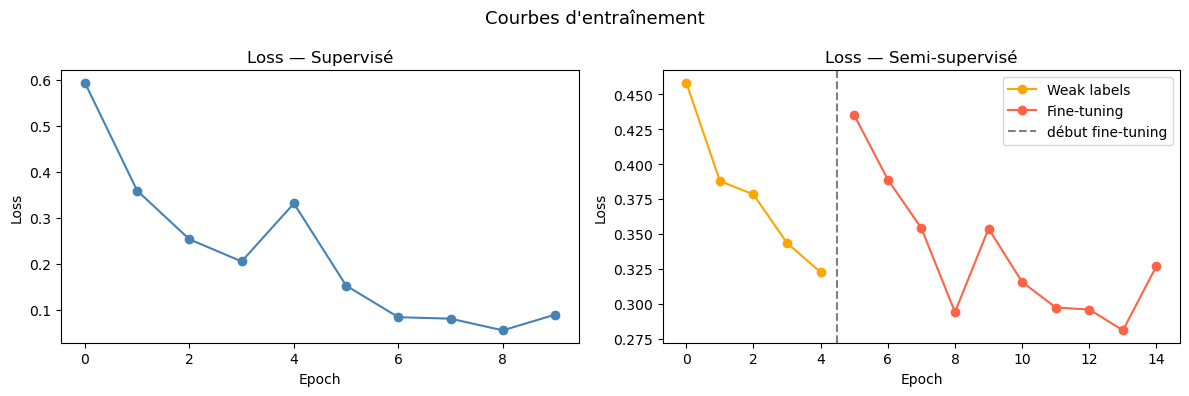

In [ ]:
# Courbes de loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(historique_sup, marker="o", color="steelblue")
axes[0].set_title("Loss — Supervisé")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(historique_weak, marker="o", color="orange", label="Weak labels")
axes[1].plot(range(len(historique_weak), len(historique_weak)+len(historique_fine)),
             historique_fine, marker="o", color="tomato", label="Fine-tuning")
axes[1].axvline(x=len(historique_weak)-0.5, color="gray", linestyle="--", label="début fine-tuning")
axes[1].set_title("Loss — Semi-supervisé")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.suptitle("Courbes d'entraînement", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
# Rapport de classification détaillé
print("=== Supervisé ===")
print(classification_report(y_test, preds_sup, target_names=["Normal", "Cancer"]))

print("=== Semi-supervisé ===")
print(classification_report(y_test, preds_semi, target_names=["Normal", "Cancer"]))

=== Supervisé ===
              precision    recall  f1-score   support

      Normal       0.71      1.00      0.83        10
      Cancer       1.00      0.60      0.75        10

    accuracy                           0.80        20
   macro avg       0.86      0.80      0.79        20
weighted avg       0.86      0.80      0.79        20

=== Semi-supervisé ===
              precision    recall  f1-score   support

      Normal       1.00      0.90      0.95        10
      Cancer       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



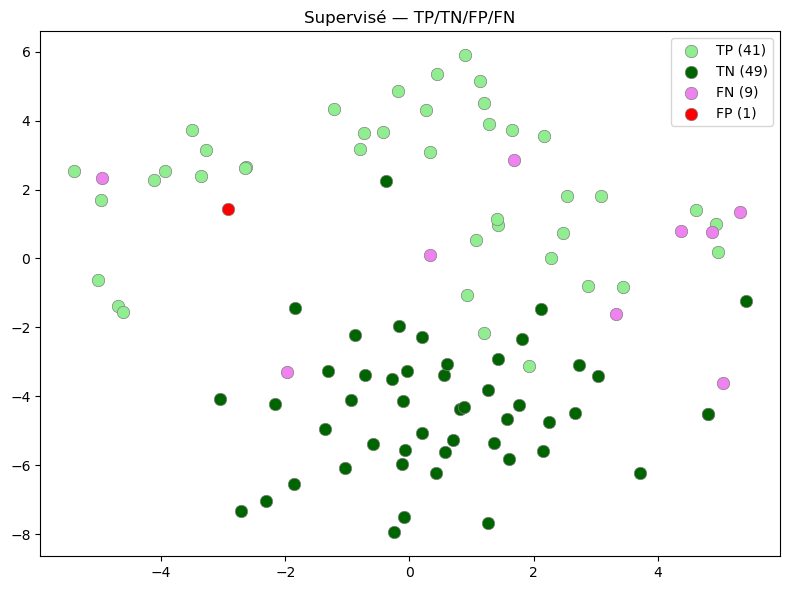

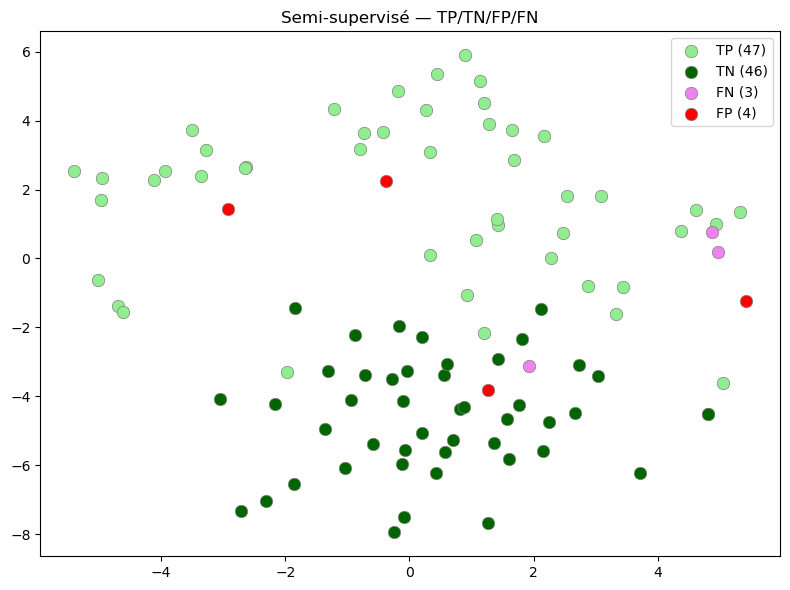

In [ ]:

feat_2d = np.load(DIR_OUTPUT / "tsne_label_2d.npy")

def plot_tp_tn_fp_fn(feat_2d, vrais, predits, titre):
    couleurs_detail = []
    for vrai, predit in zip(vrais, predits):
        if vrai == 1 and predit == 1:
            couleurs_detail.append(("lightgreen", "TP"))
        elif vrai == 0 and predit == 0:
            couleurs_detail.append(("darkgreen", "TN"))
        elif vrai == 1 and predit == 0:
            couleurs_detail.append(("violet", "FN"))
        else:
            couleurs_detail.append(("red", "FP"))

    plt.figure(figsize=(8, 6))
    for couleur, label_txt in [("lightgreen", "TP"), ("darkgreen", "TN"), ("violet", "FN"), ("red", "FP")]:
        masque = [i for i, c in enumerate(couleurs_detail) if c[0] == couleur]
        plt.scatter(feat_2d[masque, 0], feat_2d[masque, 1],
                    c=couleur, label=f"{label_txt} ({len(masque)})", s=80,
                    edgecolors="gray", linewidths=0.5)
    plt.title(titre)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_tp_tn_fp_fn(feat_2d, labels_all, preds_sup_all,  "Supervisé — TP/TN/FP/FN")
plot_tp_tn_fp_fn(feat_2d, labels_all, preds_semi_all, "Semi-supervisé — TP/TN/FP/FN")

## 9. Bilan

| Modèle | Accuracy | F1-score | Observations |
|---|---|---|---|
| Supervisé | 0.86 | 0.79 | entraîné sur 80 images |
| Semi-supervisé | 0.95 | 0.95 | pré-entraîné sur 1406 weak labels + affiné |

**Interprétation :** Modele Semi-supervisé donne de meilleurs predictions (mais testé/validé sur petit volume: 20 images).